In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Exploratory data analysis (EDA): Getting the Headcount for the data values by State

### Top 5 states:
Exploratory data analysis (EDA) to determine which states appear most often in the pollution dataset.

In [47]:
df = pd.read_csv("pollution_2000_2023.csv")
state_counts = df["State"].value_counts()

top_5_states = state_counts.head(5)
print(top_5_states)

State
California      201244
Pennsylvania     54142
Texas            38980
Arizona          25118
New York         22685
Name: count, dtype: int64


### Understanading the Shape:
Basic data inspection and validation before cleaning the data/building a machine learning model.

In [48]:
#creates a new clean copy of the dataset
df_clean = df.copy()

# Displays the dataset's dimensions as (rows/records, columns/features)
print("--- Dataset DIMENSIONS ---")
print(df_clean.shape, "\n") 
# Shows the first 5 rows of the dataset to verify that the data loaded correctly/see what the columns look like
print("--- Dataset HEAD ---")
print(df_clean.head(), "\n")
# Displays a summary of the dataset (Column names, Data types, # of non-null values, Memory usage
print("--- Dataset INFO ---")
print(df_clean.info())

--- Dataset DIMENSIONS ---
(665414, 22) 

--- Dataset HEAD ---
   Unnamed: 0        Date                                  Address    State  \
0           0  2000-01-01  1645 E ROOSEVELT ST-CENTRAL PHOENIX STN  Arizona   
1           1  2000-01-02  1645 E ROOSEVELT ST-CENTRAL PHOENIX STN  Arizona   
2           2  2000-01-03  1645 E ROOSEVELT ST-CENTRAL PHOENIX STN  Arizona   
3           3  2000-01-04  1645 E ROOSEVELT ST-CENTRAL PHOENIX STN  Arizona   
4           4  2000-01-05  1645 E ROOSEVELT ST-CENTRAL PHOENIX STN  Arizona   

     County     City   O3 Mean  O3 1st Max Value  O3 1st Max Hour  O3 AQI  \
0  Maricopa  Phoenix  0.019765             0.040               10      37   
1  Maricopa  Phoenix  0.015882             0.032               10      30   
2  Maricopa  Phoenix  0.009353             0.016                9      15   
3  Maricopa  Phoenix  0.015882             0.033                9      31   
4  Maricopa  Phoenix  0.007353             0.012                9      11   


### Top cities:
Finding the cities with the most pollution measurements/records in the dataset.

In [49]:
city_counts = (
    df_clean.groupby(["State", "City"]) # Groups all rows by their state-city combination
    .size() # Counts how many records belong to each group
    .sort_values(ascending=False) # Sorts the counts from largest to smallest
)

# Prints the top 20 state-city combinations with the most records
print(city_counts.head(20))

State                 City             
California            Los Angeles          19624
New York              New York             16811
California            Rubidoux             15671
Arizona               Phoenix              14544
Hawaii                Not in a city        12904
Arkansas              North Little Rock    11277
Texas                 Houston              11151
North Carolina        Charlotte            10536
District Of Columbia  Washington           10517
Texas                 El Paso              10366
Utah                  Salt Lake City        9338
Ohio                  Cleveland             8749
California            Concord               8543
                      Vallejo               8453
                      Bethel Island         8432
Arizona               Tucson                8401
California            Capitan               8372
                      Lompoc                8274
Louisiana             Baton Rouge           8254
California            San Pab

### (real code BEGINS HERE:)
### Top Cities
Looking at the most common cities within each of the top 5 states that contribute the most records.

In [50]:
# List containing the five states that had the most records in earlier analysis
states = ["California", "Pennsylvania", "Texas", "Arizona", "New York"]

for state in states:
    # Count how many records belong to each city in that state
    # Sort them from highest to lowest
    # Return the top 10 cities for that state
    state_data = df_clean[df_clean["State"] == state]

    print(f"\n{state}")
    print(state_data["City"].value_counts().head(10))


California
City
Los Angeles      19624
Rubidoux         15671
Concord           8543
Vallejo           8453
Bethel Island     8432
Capitan           8372
Lompoc            8274
San Pablo         8122
Calexico          8003
Victorville       7836
Name: count, dtype: int64

Pennsylvania
City
Philadelphia     6403
Johnstown        6082
Pittsburgh       4997
Not in a city    4797
York             4479
Charleroi        3995
Bristol          3200
Erie             2969
Scranton         2161
Freemansburg     1918
Name: count, dtype: int64

Texas
City
Houston          11151
El Paso          10366
Dallas            7398
Deer Park         4246
Waco              3542
San Antonio        893
Not in a city      841
Austin             543
Name: count, dtype: int64

Arizona
City
Phoenix       14544
Tucson         8401
Scottsdale     2173
Name: count, dtype: int64

New York
City
New York         16811
Holtsville        4574
Not in a city     1016
Rochester          284
Name: count, dtype: int64


In [51]:
# Updated top 5 cities within top 5 states; list of (State, City) pairs
cities = [
    ("California", "Los Angeles"),
    ("Pennsylvania", "Philadelphia"),
    ("Texas", "Houston"),
    ("Arizona", "Phoenix"),
    ("New York", "New York")
]

In [52]:
for state, city in cities:
    # For each pair, filter the dataset containing only the top city records from their respective state
    subset = df_clean[
        (df_clean["State"] == state) &
        (df_clean["City"] == city)
    ]

    print(f"\n{city}, {state}")
    print("- Observations:", len(subset)) # Number of rows/records for current city
    # Find the earliest/latest dates in that city's records
    print("- Start date:", subset["Date"].min())
    print("- End date:", subset["Date"].max())


Los Angeles, California
- Observations: 19624
- Start date: 2000-03-01
- End date: 2023-06-30

Philadelphia, Pennsylvania
- Observations: 6403
- Start date: 2000-01-01
- End date: 2023-06-30

Houston, Texas
- Observations: 11151
- Start date: 2000-01-01
- End date: 2023-06-30

Phoenix, Arizona
- Observations: 14544
- Start date: 2000-01-01
- End date: 2023-09-30

New York, New York
- Observations: 16811
- Start date: 2000-01-01
- End date: 2023-08-31


# Actual Preprocessing
Transitioning from EDA to preprocessing (preparing the data for machine learning).

In [53]:
#clean the data and ensure date is correct
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    errors="coerce"
)
print("Invalid dates:", df_clean["Date"].isna().sum())

#remove address and county (unused columns)
df_clean = df_clean.drop(columns=["Address"])
df_clean = df_clean.drop(columns=["County"])


#set timeperiod: 2000 to 2023 (defining the desired date range)
start_date = "2000-01-01"
end_date = "2023-06-30"

#clean (only keep rows that fall within the selected date range)
df_selected = df_clean[
    (df_clean["Date"] >= start_date) &
    (df_clean["Date"] <= end_date) &
    (
        df_clean[["State", "City"]]
        .apply(tuple, axis=1)
        .isin(cities)
    )
].copy()

Invalid dates: 0


In [58]:
# Diminesions of final cleaned dataset
print("Filtered dataset:", df_selected.shape, "\n")
# Number of records for each top state/city pair
print(df_selected.groupby(["State", "City"]).size())

Filtered dataset: (68348, 20) 

State         City        
Arizona       Phoenix         14452
California    Los Angeles     19624
New York      New York        16718
Pennsylvania  Philadelphia     6403
Texas         Houston         11151
dtype: int64


In [59]:
#checking for missing/incorrect/duplicate values one more time
missing_values = df_selected.isnull().sum()
print(missing_values[missing_values > 0], "\n")

# Computes the percentage of missing values in each column
missing_percent = (
    df_selected.isnull().mean() * 100
).sort_values(ascending=False)
print(missing_percent)

# Checks whether any rows are exact duplicates of another row
print("\nDuplicate rows:", df_selected.duplicated().sum())

Series([], dtype: int64) 

Unnamed: 0           0.0
Date                 0.0
NO2 1st Max Hour     0.0
NO2 1st Max Value    0.0
NO2 Mean             0.0
SO2 AQI              0.0
SO2 1st Max Hour     0.0
SO2 1st Max Value    0.0
SO2 Mean             0.0
CO AQI               0.0
CO 1st Max Hour      0.0
CO 1st Max Value     0.0
CO Mean              0.0
O3 AQI               0.0
O3 1st Max Hour      0.0
O3 1st Max Value     0.0
O3 Mean              0.0
City                 0.0
State                0.0
NO2 AQI              0.0
dtype: float64

Duplicate rows: 0


In [60]:
# Define the columns that contain pollution measurements
pollutant_columns = [
    "O3 Mean",
    "CO Mean",
    "SO2 Mean",
    "NO2 Mean",
    "O3 AQI",
    "CO AQI",
    "SO2 AQI",
    "NO2 AQI"
]

# Convert columns to numeric
for col in pollutant_columns:
    df_selected[col] = pd.to_numeric(
        df_selected[col],
        errors="coerce"
    )
# Print a statistical summary for each pollution feature
print(df_selected[pollutant_columns].describe())

            O3 Mean       CO Mean      SO2 Mean      NO2 Mean        O3 AQI  \
count  68348.000000  68348.000000  68348.000000  68348.000000  68348.000000   
mean       0.025578      0.418131      1.979001     18.400088     37.277287   
std        0.012082      0.312506      3.216813     10.395482     21.255612   
min        0.000000     -0.400000     -1.725000     -0.152174      0.000000   
25%        0.016353      0.212500      0.237500     10.475000     24.000000   
50%        0.025235      0.333333      0.820833     16.712771     34.000000   
75%        0.034118      0.533333      2.347826     24.791667     44.000000   
max        0.089647      4.246667     53.500000     98.130435    222.000000   

             CO AQI       SO2 AQI       NO2 AQI  
count  68348.000000  68348.000000  68348.000000  
mean       7.046512      6.388439     31.959238  
std        5.828278     11.181706     15.009510  
min        0.000000      0.000000      0.000000  
25%        3.000000      0.000000     

### Preforming EDA 

In [ ]:
# Convert Date column to datetime object
df_selected["Date"] = pd.to_datetime(df_selected["Date"])

# Extract the year from the date
df_selected["Year"] = df_selected["Date"].dt.year

In [ ]:
# Calculate yearly average pollution levels
yearly_pollution = df_selected.groupby(
    ["Year", "City"]
)[["O3 Mean", "CO Mean", "SO2 Mean", "NO2 Mean"]].mean().reset_index()

In [69]:
print(yearly_pollution.head(), "\n")
print(yearly_pollution.shape)

   Year          City   O3 Mean   CO Mean  SO2 Mean   NO2 Mean
0  2000       Houston  0.021800  0.382014  6.216671  16.822696
1  2000   Los Angeles  0.020179  1.071678  1.346163  40.105582
2  2000      New York  0.019048  0.624448  7.505418  26.696346
3  2000  Philadelphia  0.017296  0.569723  5.066385  25.662834
4  2000       Phoenix  0.024682  1.008682  2.318968  29.109833 

(116, 6)


In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Create a working copy
eda_df = df_selected.copy()

# Convert Date to datetime
eda_df["Date"] = pd.to_datetime(eda_df["Date"])

# Extract date features
eda_df["Year"] = eda_df["Date"].dt.year
eda_df["Month"] = eda_df["Date"].dt.month

# Create seasons
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

eda_df["Season"] = eda_df["Month"].map(season_map)

# Define pollutant columns
pollutants = ["O3 Mean", "CO Mean", "SO2 Mean", "NO2 Mean"]

aqi_columns = ["O3 AQI", "CO AQI", "SO2 AQI", "NO2 AQI"]

### Line Graphs of MEAN Polution Trends over Year BY City

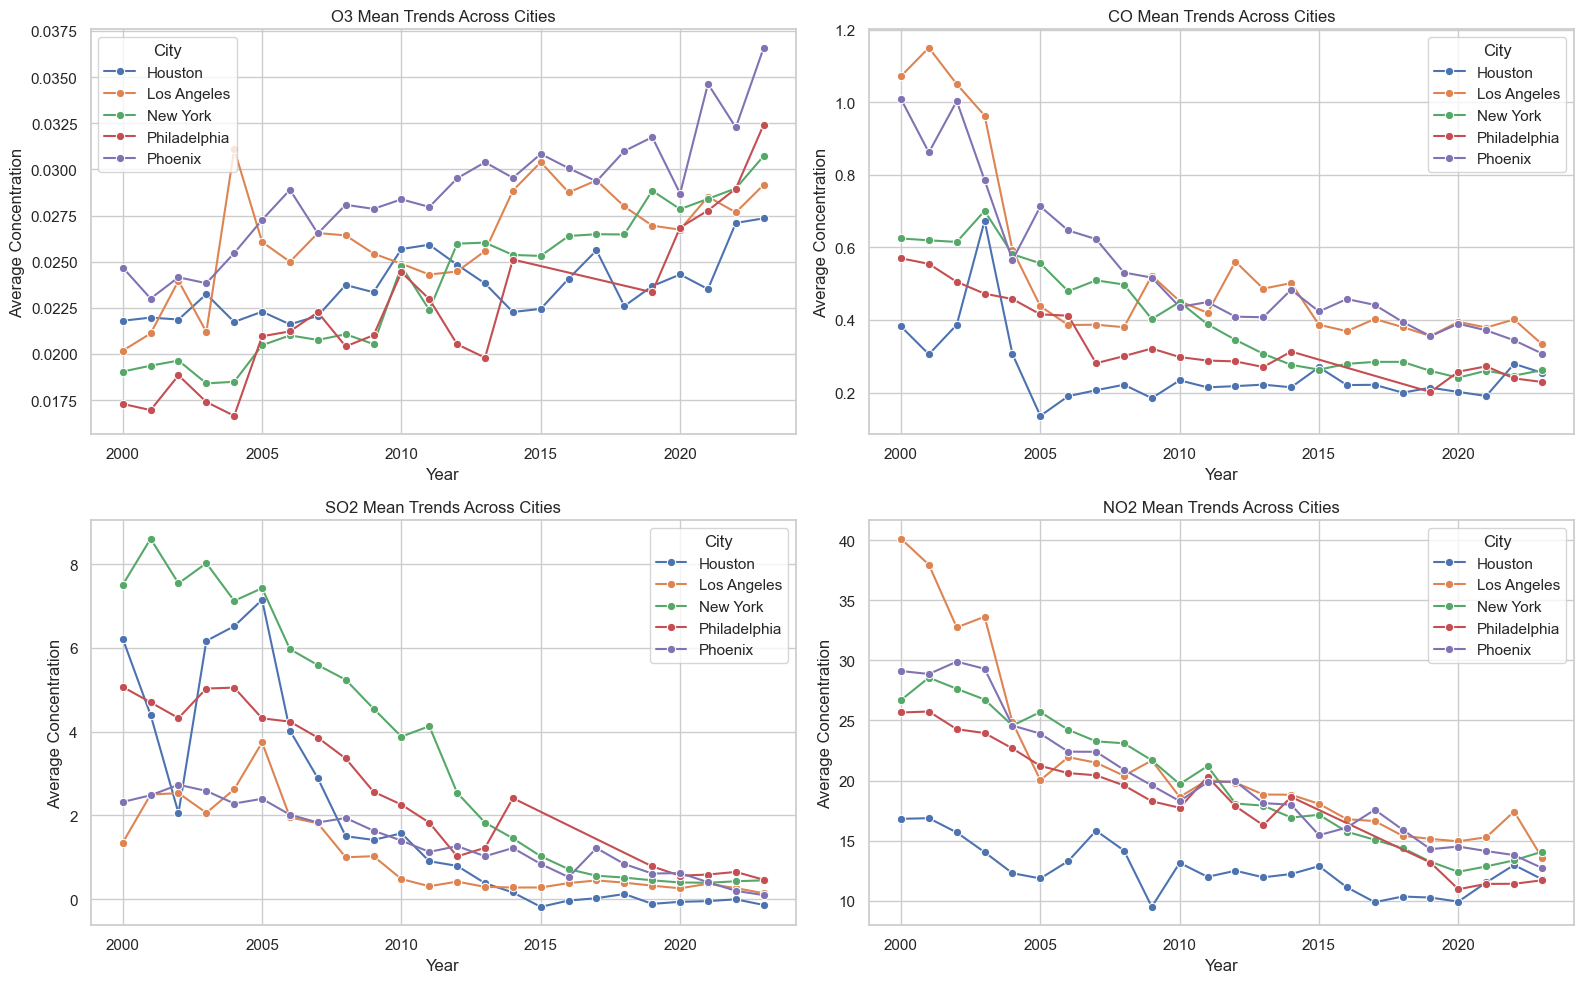

In [68]:
yearly_pollution = (
    eda_df.groupby(["Year", "City"])[pollutants]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Flatten axes so we can loop through them
axes = axes.flatten()

for i, pollutant in enumerate(pollutants):

    sns.lineplot(
        data=yearly_pollution,
        x="Year",
        y=pollutant,
        hue="City",
        marker="o",
        ax=axes[i]
    )

    axes[i].set_title(f"{pollutant} Trends Across Cities")
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Average Concentration")

    # Show legend
    axes[i].legend(title="City")

# Adjust spacing
plt.tight_layout()

plt.show()

### Correlation between pollutants ad AQI: this can allow us to find which of the pollutants actually impact the Air Quality Index the most

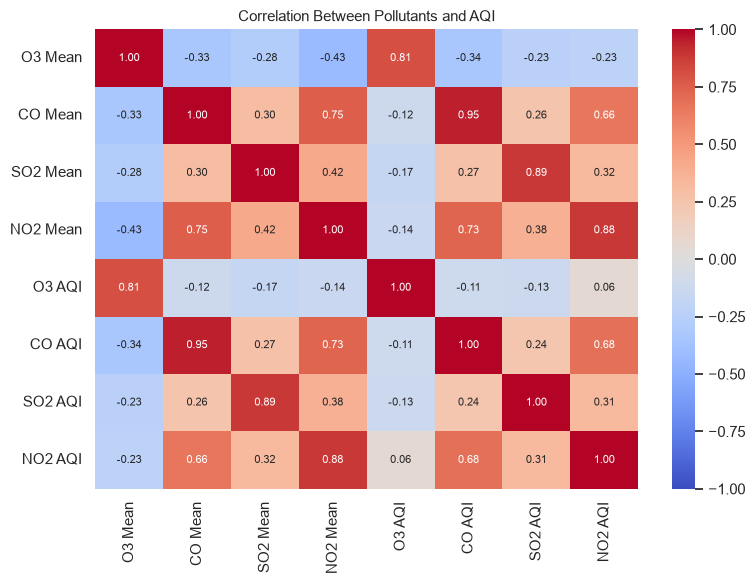

In [ ]:
correlation_columns = pollutants + aqi_columns

correlation = eda_df[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8}
)

plt.title("Correlation Between Pollutants and AQI", fontsize=11)
plt.tight_layout()
plt.show()

We can see that CO contributes the most to its corresponding CO AQI incomparison to the other pollutants, but all are still very important and correlate with the AQI

### Comparing EACH city's pollutant mean

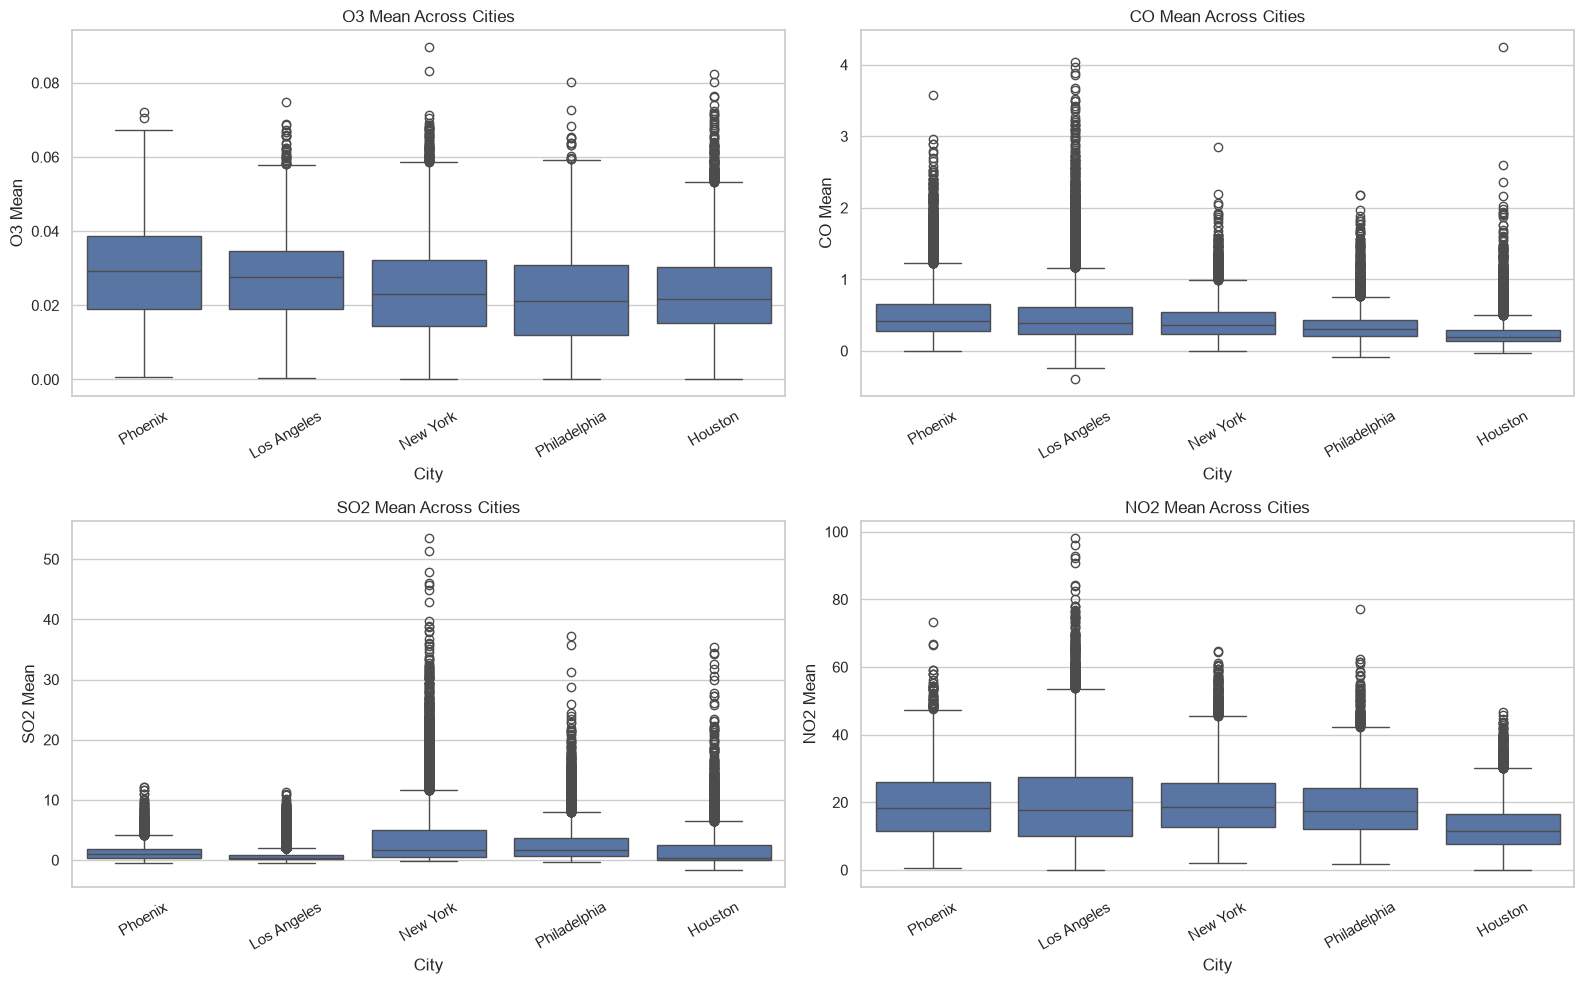

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, pollutant in enumerate(pollutants):

    sns.boxplot(
        data=eda_df,
        x="City",
        y=pollutant,
        ax=axes[i]
    )

    axes[i].set_title(f"{pollutant} Across Cities")
    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# Baseline Ridge Regression model
We shall select "O3 AQI" as our target for Ridge Regression.

### Select Features

In [76]:
# %pip install scikit-learn
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

### Create Features and Target

In [77]:
feature_cols = [
    "O3 Mean",
    "CO Mean",
    "SO2 Mean",
    "NO2 Mean",
    "Year"
]

target = "O3 AQI"

X = df_selected[feature_cols]
y = df_selected[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (68348, 5)
Target shape: (68348,)


### Train/Test Split
A standard 80/20 split:

In [78]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 54678
Testing samples: 13670


### Scale Features

In [79]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Train Baseline Ridge Model

In [80]:
ridge = Ridge(alpha=1.0) # Ridge regularization strength.

ridge.fit(X_train_scaled, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


### Make Predictions

In [81]:
y_pred = ridge.predict(X_test_scaled)

### Evaluate Performance

In [82]:
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Ridge Regression Results")
print("------------------------")
print("MAE :", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R²  :", round(r2, 3))

Ridge Regression Results
------------------------
MAE : 7.585
RMSE: 11.302
R²  : 0.717


### Feature Importance

In [83]:
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": ridge.coef_
})

coef_df = coef_df.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

print(coef_df)

    Feature  Coefficient
0   O3 Mean    19.528598
3  NO2 Mean     5.788297
2  SO2 Mean    -0.612295
4      Year    -0.383587
1   CO Mean    -0.358542


### Actual vs Predicted Plot

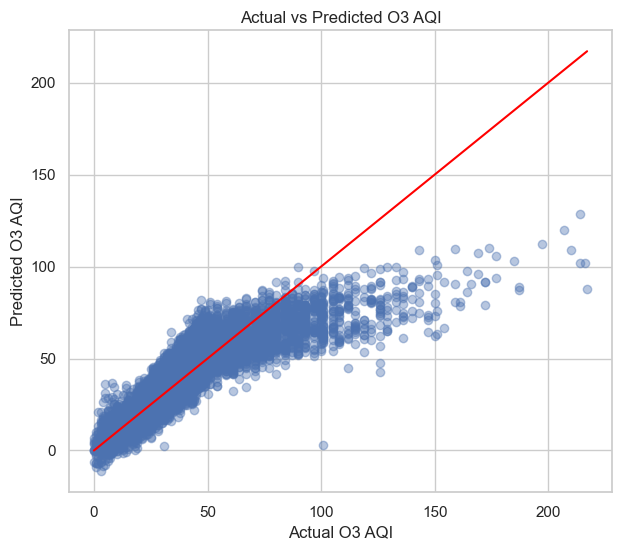

In [84]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.xlabel("Actual O3 AQI")
plt.ylabel("Predicted O3 AQI")
plt.title("Actual vs Predicted O3 AQI")

plt.show()